# 4 · Planning experiments

The calibrated and scenario models are used to ask two planning questions:
1. **Which measures would have contained the 1978 school outbreak?** Each intervention is simulated for every accepted posterior draw of notebook 3 (with 4 seeds each), so the comparison carries the calibration uncertainty. Runs that fizzle out count, because an intervention can make a major outbreak less likely.
2. **How does hospital capacity change outcomes in the lower respiratory scenario?** Regular bed capacity is swept from 5 to 80 beds per 1,000 agents under two response policies: the report's isolation phase, which starts when hospitals are full, and no isolation phase.

In [1]:
from IPython.display import Image, display
import pandas as pd

from epidemic_abm import pipeline

pd.set_option("display.precision", 4)
FIGURES = pipeline.FIGURES


def show(name):
    display(Image(filename=str(FIGURES / name)))


interventions, capacity = pipeline.experiments()   # uses results/calibration.json from notebook 3
interventions.round(3)

,intervention,boys_ill_mean,boys_ill_low,boys_ill_high,major_outbreak_probability,boys_ill_if_major_median,peak_in_bed_mean,runs
0,No intervention,388.890,269.95,559.55,0.990,371.0,280.848,400
1,Dining hall closed,386.458,261.95,561.00,0.985,369.0,230.022,400
2,Dining hall at half capacity,386.840,263.00,563.05,0.985,371.0,279.040,400
3,Tables of at most 4,390.405,266.95,558.05,0.992,370.0,261.998,400
4,Hygiene and masks (−30% transmission),384.440,267.90,563.30,0.980,370.5,272.678,400
5,Isolate at first symptoms (50% a day),202.685,0.00,540.05,0.520,372.0,112.788,400
6,Half capacity + isolation,205.668,0.00,540.20,0.538,365.0,114.285,400


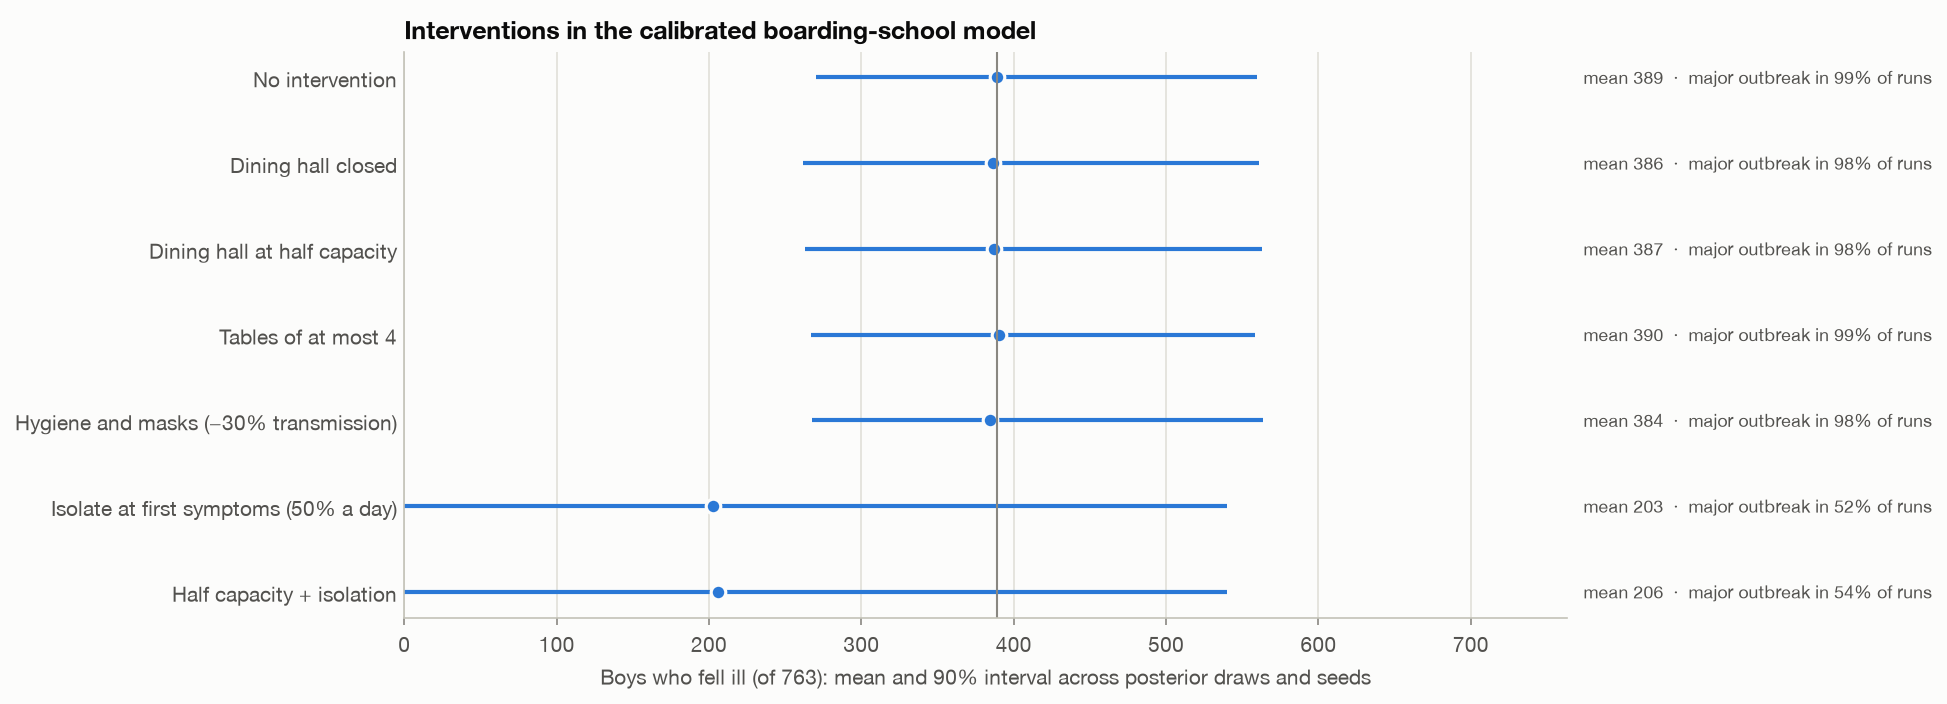

In [2]:
show("school_interventions.png")

- **Isolating boys at their first symptoms is the only measure that clearly works.** With a 50% daily chance of isolating at first symptoms, the mean number of boys ill falls from 389 to 203.
  - It works by preventing take-off: the chance of a major outbreak falls from 99% to 52%.
  - Once an outbreak does take off, it is about as large (median 372 vs 371 boys).
  - Halving dining capacity on top adds nothing (mean 206).
- **Closing the dining hall** barely changes the total (mean 386). Dormitory contacts alone sustain transmission, although the peak in bed is lower (230 vs 281).
- **A 30% cut in per-contact transmission** (hygiene, masks) also has little effect (mean 384). The calibrated model is in a contact-limited regime where transmission per contact is near-certain (notebook 3), so only fewer contacts of infectious boys help. This conclusion inherits the weak identification of the transmission scale and should not be read as evidence about masks in general.

In [3]:
capacity.round(3)

,policy,beds,beds_per_1000,deaths_median,deaths_low,deaths_high,max_turned_away_median,attack_rate_median,epidemic_day_median
0,Isolation when hospitals are full (report),75,5.0,5166.5,5026.20,5291.80,5129.5,0.766,6.0
1,Isolation when hospitals are full (report),150,10.0,5123.5,4999.70,5278.20,5027.0,0.767,6.0
2,Isolation when hospitals are full (report),300,20.0,5082.0,4936.85,5206.70,4833.0,0.764,6.0
3,Isolation when hospitals are full (report),600,40.0,5388.5,5225.80,5513.20,5027.5,0.838,7.0
4,Isolation when hospitals are full (report),1200,80.0,5549.5,5428.55,5644.35,4787.5,0.893,8.0
5,No isolation phase,75,5.0,6696.5,6540.75,6759.15,6932.5,1.000,6.0
6,No isolation phase,150,10.0,6661.0,6538.35,6789.20,6850.0,1.000,6.0
7,No isolation phase,300,20.0,6617.5,6488.95,6676.80,6673.0,1.000,6.0
8,No isolation phase,600,40.0,6425.5,6350.20,6525.10,6293.5,1.000,7.0
9,No isolation phase,1200,80.0,6224.5,6132.65,6328.60,5570.5,1.000,8.0


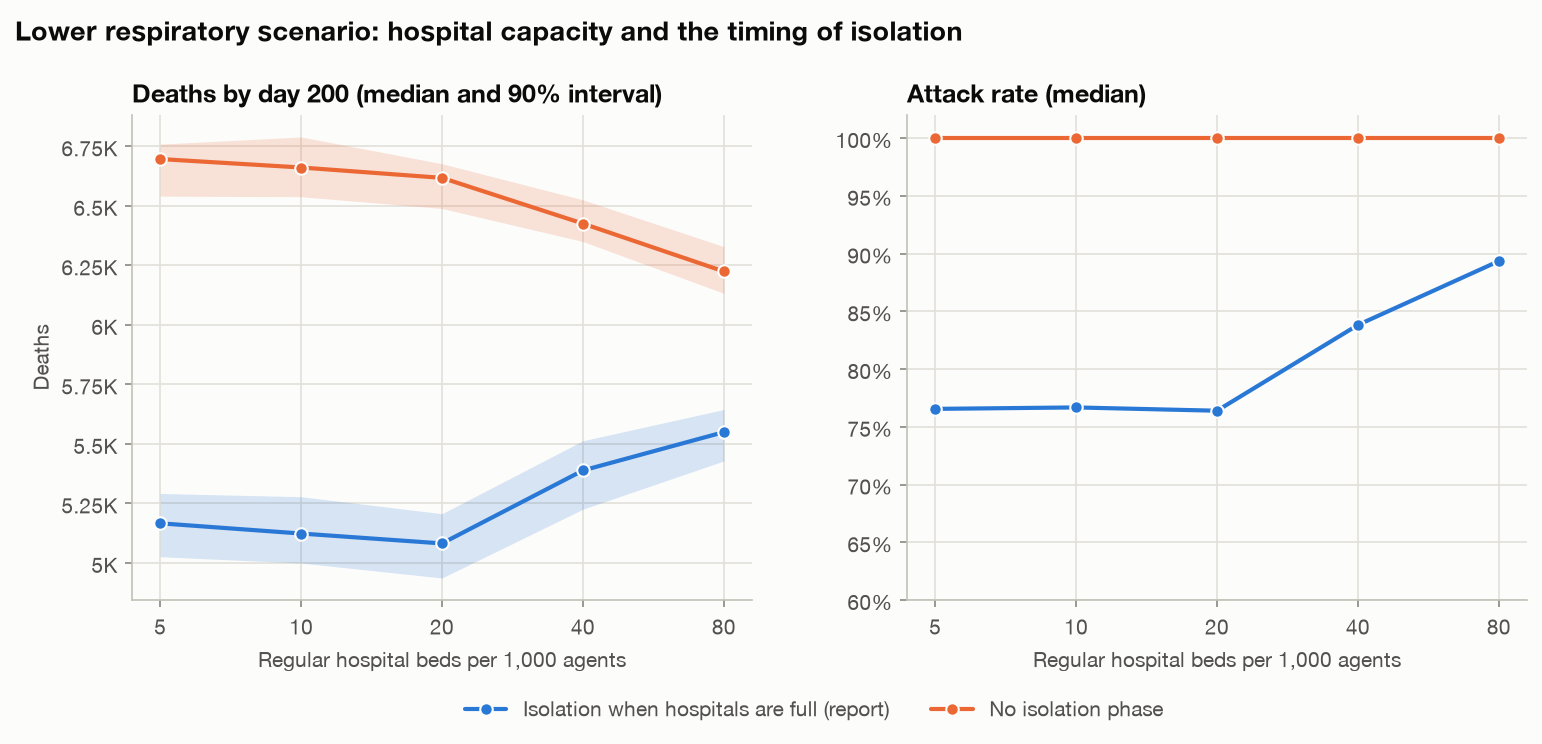

In [4]:
show("lrti_hospital_capacity.png")

- **Without an isolation phase,** more beds save lives: deaths fall from 6,618 at 20 beds per 1,000 to 6,224 at 80, while everyone is infected.
- **With the report's response,** isolation starts when hospitals are full, so extra beds delay the epidemic day (day 6 at 20 beds per 1,000, day 8 at 80). The outbreak spreads further: the attack rate rises from 76% to 89% and deaths from 5,082 to 5,550.
- **Isolation saves far more lives than beds do:** about 1,536 deaths at 20 beds per 1,000.
- **Planning implication:** tie the isolation trigger to an early signal, such as severe cases or first symptoms, rather than to hospital saturation. Otherwise investing in capacity postpones the response.